# Trolls, Haters, or Teammates — Classifying Sentiment in PvP Game Chat

Re-implementation of the paper on **League of Legends + DOTA 2** in-game chat.

Each chat message is classified into one of three classes:

| Label | Class | Examples |
|---|---|---|
| 0 | Neutral / positive | `gg wp`, `ty`, `nice gank` |
| 1 | Negative attitude | `noob team`, `report jax`, `stop feeding` |
| 2 | Derogatory | slurs, sexist / racist / homophobic abuse, `kys` |

**Pipeline:** load → clean → 60/20/20 split → TF-IDF → models from the paper → compare → improve KNN

| Paper section | Model(s) in this notebook |
|---|---|
| 4.1 Baseline | Binary SVM (linear, RBF, polynomial) |
| 4.2 Naive Bayes | NB with a fixed toxic dictionary, then NB with TF-IDF |
| 4.3 KNN | K = 1, 2, 3, 6 (Euclidean distance) |
| 4.4 Random Forest | Gini, Entropy, Entropy with max depth 32 |
| Our addition | Improved KNN (TruncatedSVD + grid search) |

## 0. Setup



In [2]:
import os, re, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
CLASS_NAMES = ["Neutral/Positive", "Negative attitude", "Derogatory"]
os.makedirs("outputs", exist_ok=True)

DATA_PATH = "data/pvp_chat_labelled.csv"
if not os.path.exists(DATA_PATH):
    try:                                   # Google Colab: upload the CSV
        from google.colab import files
        up = files.upload()
        DATA_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put pvp_chat_labelled.csv inside a data/ folder next to this notebook")
print("Using", DATA_PATH)

Saving pvp_chat_labelled.csv to pvp_chat_labelled.csv
Using pvp_chat_labelled.csv


## 1. Load the data



(33000, 3)


,text,game,label
12144,fuckign french homos,LoL,2
27820,so bad snyper,DOTA2,1
1827,dont fucking pick suppro dogs,DOTA2,1
8116,because teemo raped him,LoL,2
26529,nu ne defay bratish,DOTA2,0
13663,report pls shadow,DOTA2,1
6405,i wooped you ass dude,DOTA2,1
16935,so speak english ;),LoL,0
31605,and ur mum,LoL,2
31111,fuck ya bitch,LoL,2


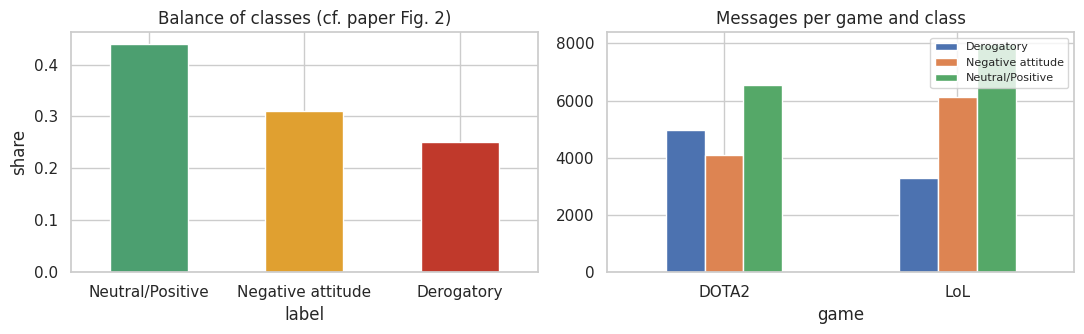

In [3]:
df = pd.read_csv(DATA_PATH)
df["text"] = df["text"].astype(str)
print(df.shape)
display(df.sample(10, random_state=1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
(df.label.value_counts(normalize=True).sort_index()
   .rename(index=dict(enumerate(CLASS_NAMES))).plot.bar(ax=ax[0], color=["#4C9F70", "#E0A030", "#C0392B"], rot=0))
ax[0].set_title("Balance of classes (cf. paper Fig. 2)"); ax[0].set_ylabel("share")
pd.crosstab(df.game, df.label.map(dict(enumerate(CLASS_NAMES)))).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Messages per game and class"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("outputs/class_balance.png", dpi=150); plt.show()

## 2. Pre-processing and 60/20/20 split


In [4]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)          # loooool -> lool
    t = re.sub(r"[^a-z0-9!?*@' ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].map(clean)
print("dropping", (df.clean == "").sum(), "messages that are empty after cleaning (only symbols/emoji)")
df = df[df.clean != ""].reset_index(drop=True)
X, y = df["clean"].values, df["label"].values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test   = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)}")

dropping 4 messages that are empty after cleaning (only symbols/emoji)
train 19797 | val 6599 | test 6600


## 3. TF-IDF encoding (paper §3.1)


In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True,
                        token_pattern=r"(?u)\b\w+\b")          # keep 1-letter tokens like 'u', 'r'
Xtr = tfidf.fit_transform(X_train); Xva = tfidf.transform(X_val); Xte = tfidf.transform(X_test)
print("TF-IDF matrix:", Xtr.shape)

# helpers shared by every model
results = []                       # one row per model -> comparison tables
def evaluate(name, model, Xv, Xt, yv=y_val, yt=y_test, store=True):
    t0 = time.time()
    pv, pt = model.predict(Xv), model.predict(Xt)
    row = {"Model": name, "Val acc": accuracy_score(yv, pv), "Test acc": accuracy_score(yt, pt)}
    if len(np.unique(yt)) == 3:
        for k, f in enumerate(f1_score(yt, pt, average=None, labels=[0, 1, 2])): row[f"F1 class {k}"] = f
        row["Macro F1"] = f1_score(yt, pt, average="macro")
    if store: results.append(row)
    print(f"{name:<32} val={row['Val acc']:.4f}  test={row['Test acc']:.4f}   ({time.time()-t0:.1f}s predict)")
    return pt

def plot_cm(y_true, y_pred, title, fname=None):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    labels = CLASS_NAMES if cm.shape[0] == 3 else ["Neutral/Pos", "Toxic"]
    plt.figure(figsize=(4.6, 3.8))
    sns.heatmap(cm, annot=True, fmt=".3f", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(title); plt.tight_layout()
    if fname: plt.savefig(f"outputs/{fname}", dpi=150)
    plt.show()

TF-IDF matrix: (19797, 5000)


## 4. Baseline — binary SVM (paper §4.1, Table 2)


  fit 0.1s
SVM (linear kernel)        test acc = 0.9856
  fit 80.0s
SVM (rbf kernel)           test acc = 0.9771
  fit 72.1s
SVM (polynomial kernel)    test acc = 0.9527


,Model,Val acc,Test acc
0,SVM (linear kernel),0.9827,0.9856
1,SVM (rbf kernel),0.9744,0.9771
2,SVM (polynomial kernel),0.9508,0.9527


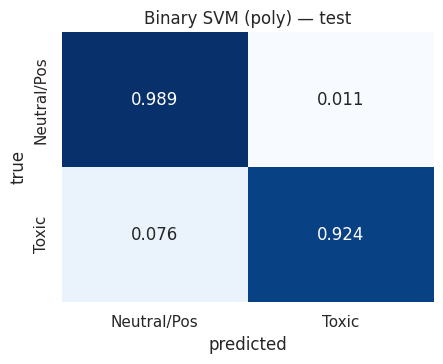

In [6]:
yb_train, yb_val, yb_test = (y_train > 0).astype(int), (y_val > 0).astype(int), (y_test > 0).astype(int)
svm_results = []
for name, m in [("SVM (linear kernel)", LinearSVC(C=1.0, random_state=SEED)),
                ("SVM (rbf kernel)",    SVC(kernel="rbf", C=1.0, gamma="scale")),
                ("SVM (polynomial kernel)", SVC(kernel="poly", degree=2, C=1.0, gamma="scale"))]:
    t0 = time.time(); m.fit(Xtr, yb_train); print(f"  fit {time.time()-t0:.1f}s")
    pv, pt = m.predict(Xva), m.predict(Xte)
    svm_results.append({"Model": name, "Val acc": accuracy_score(yb_val, pv), "Test acc": accuracy_score(yb_test, pt)})
    print(f"{name:<26} test acc = {svm_results[-1]['Test acc']:.4f}")
svm_table = pd.DataFrame(svm_results); display(svm_table.round(4))
plot_cm(yb_test, pt, "Binary SVM (poly) — test", "cm_svm_binary.png")

## 5. Naive Bayes (paper §4.2)


128 dictionary terms
Naive Bayes (dictionary)         val=0.9224  test=0.9230   (0.0s predict)


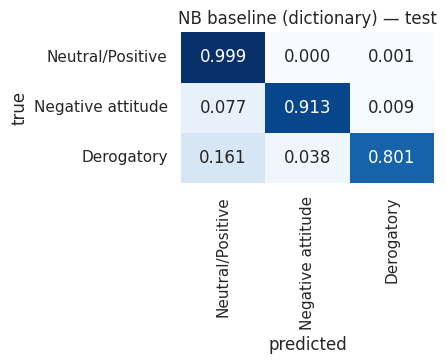

Naive Bayes (TF-IDF)             val=0.9026  test=0.9050   (0.0s predict)


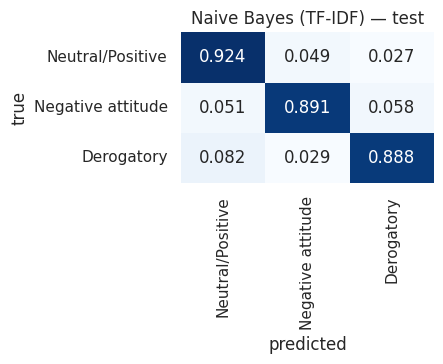

Neutral/Positive  : kak, eto, ne, pra, com, bien, che, ti, di, why no, za, daun
Negative attitude : worst, report, feed, noob, is bad, wtf, so bad, stop feed, idiot, the worst, a bad, noobs
Derogatory        : retard, bitch, gay, retarded, tard, pussy, retards, monkey, cunt, faggot, nigga, rape


In [7]:
GAMING_DICT = sorted(set('''
gg wp ggwp gj ty thx thanks nice np gl hf glhf lol xd haha lmao ok ez sry sorry pls plz brb wow omg
mb good great well played care ward wards push gank help come back
noob noobs nub idiot idiots stupid dumb moron trash garbage useless feed feeder feeding inting report reported
uninstall loser pathetic worst braindead shit fuck fucking fck fk wtf stfu gtfo omfg ffs damn ass asshole dick
dog clown scrub bad terrible awful suck sucks hate shut die l2p cry crying cancer toxic bronze elo afk ff
retard retarded retards tard autist autistic mongo cunt bitch bitches whore slut hoe pussy kys rape raped
nigger niggers nigga fag faggot gay homo jew jews monkey terrorist kitchen barbie girl mom mother motherfucker
'''.split()))
print(len(GAMING_DICT), "dictionary terms")

dict_vec = CountVectorizer(vocabulary=GAMING_DICT, token_pattern=r"(?u)\b\w+\b")
nb_dict = MultinomialNB().fit(dict_vec.transform(X_train), y_train)
pred_nb_dict = evaluate("Naive Bayes (dictionary)", nb_dict, dict_vec.transform(X_val), dict_vec.transform(X_test))
plot_cm(y_test, pred_nb_dict, "NB baseline (dictionary) — test", "cm_nb_dict.png")

nb = MultinomialNB(alpha=0.1).fit(Xtr, y_train)
pred_nb = evaluate("Naive Bayes (TF-IDF)", nb, Xva, Xte)
plot_cm(y_test, pred_nb, "Naive Bayes (TF-IDF) — test", "cm_nb_tfidf.png")

# most indicative words per class (paper: 'gg'->0, 'noob'->1, 'r*tarded'->2)
feat = np.array(tfidf.get_feature_names_out())
for k in range(3):
    top = feat[np.argsort(nb.feature_log_prob_[k] - nb.feature_log_prob_.mean(0))[::-1][:12]]
    print(f"{CLASS_NAMES[k]:<18}: {', '.join(top)}")

## 6. K-Nearest Neighbours (paper §4.3)


In [8]:
knn_models = {}
for k in [1, 2, 3, 6]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1).fit(Xtr, y_train)
    knn_models[k] = knn
    evaluate(f"KNN (K = {k})", knn, Xva, Xte)

KNN (K = 1)                      val=0.6724  test=0.6715   (13.1s predict)
KNN (K = 2)                      val=0.6581  test=0.6630   (21.3s predict)
KNN (K = 3)                      val=0.6786  test=0.6802   (10.0s predict)
KNN (K = 6)                      val=0.6530  test=0.6602   (10.0s predict)


## 7. Random Forests (paper §4.4)


In [9]:
rf_models = {}
for name, kw in [("RF (Entropy, max depth = 32)", dict(criterion="entropy", max_depth=32)),
                 ("RF (Entropy)", dict(criterion="entropy")),
                 ("RF (Gini)",    dict(criterion="gini"))]:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, **kw).fit(Xtr, y_train)
    print(f"  fit {time.time()-t0:.1f}s")
    rf_models[name] = rf
    evaluate(name, rf, Xva, Xte)

  fit 4.5s
RF (Entropy, max depth = 32)     val=0.8529  test=0.8527   (0.5s predict)
  fit 27.2s
RF (Entropy)                     val=0.9600  test=0.9629   (2.2s predict)
  fit 26.3s
RF (Gini)                        val=0.9635  test=0.9667   (2.2s predict)


## 8. Comparison of ML classifiers (paper Tables 3 & 4)

,Val acc,Test acc,F1 class 0,F1 class 1,F1 class 2,Macro F1
Model,,,,,,
Naive Bayes (dictionary),0.9224,0.9230,0.9316,0.9394,0.8834,0.9181
Naive Bayes (TF-IDF),0.9026,0.9050,0.9211,0.8985,0.8847,0.9014
KNN (K = 1),0.6724,0.6715,0.7233,0.6136,0.6245,0.6538
KNN (K = 2),0.6581,0.6630,0.7323,0.5652,0.5819,0.6265
KNN (K = 3),0.6786,0.6802,0.7355,0.6023,0.6237,0.6538
KNN (K = 6),0.6530,0.6602,0.7261,0.5539,0.5819,0.6206
"RF (Entropy, max depth = 32)",0.8529,0.8527,0.8653,0.8305,0.8514,0.8490
RF (Entropy),0.9600,0.9629,0.9726,0.9627,0.9449,0.9601
RF (Gini),0.9635,0.9667,0.9769,0.9670,0.9472,0.9637


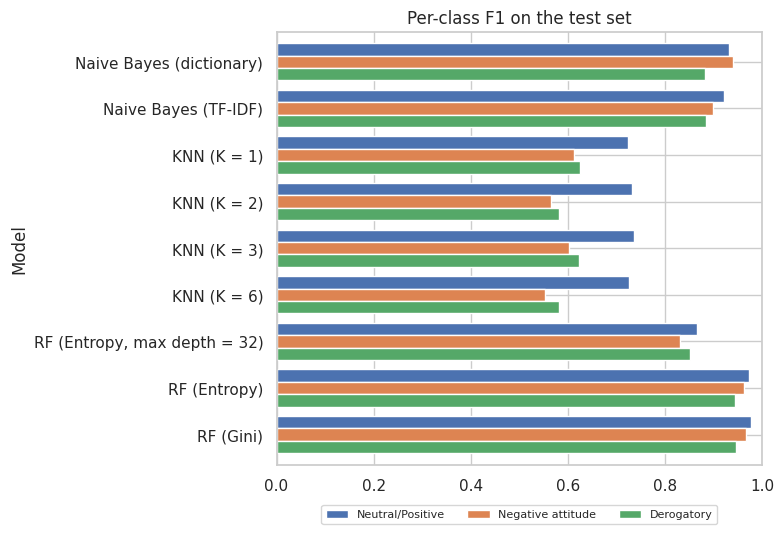

Best on validation: RF (Gini)
                   precision    recall  f1-score   support

 Neutral/Positive     0.9589    0.9955    0.9769      2904
Negative attitude     0.9614    0.9726    0.9670      2046
       Derogatory     0.9894    0.9085    0.9472      1650

         accuracy                         0.9667      6600
        macro avg     0.9699    0.9589    0.9637      6600
     weighted avg     0.9673    0.9667    0.9664      6600



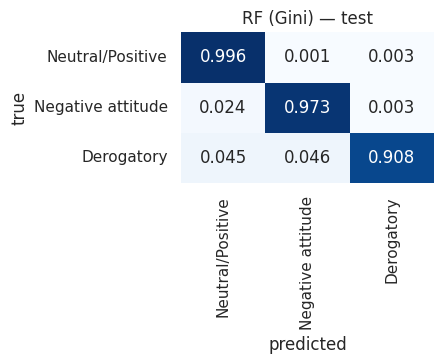

In [10]:
table = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
display(table.style.format("{:.4f}").background_gradient(cmap="Greens", subset=["Test acc", "Macro F1"]))
table.round(4).to_csv("outputs/ml_results.csv")

ax = table[["F1 class 0", "F1 class 1", "F1 class 2"]].plot.barh(figsize=(8, 5.5), width=0.8)
ax.set_xlim(0, 1.0); ax.set_title("Per-class F1 on the test set"); ax.invert_yaxis()
ax.legend(CLASS_NAMES, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig("outputs/f1_comparison.png", dpi=150); plt.show()

# best model chosen on VALIDATION accuracy (never on test)
best_name = table["Val acc"].idxmax()
all_models = {"Naive Bayes (TF-IDF)": nb, **{f"KNN (K = {k})": m for k, m in knn_models.items()}, **rf_models}
best_model = all_models.get(best_name, rf_models["RF (Gini)"])
print("Best on validation:", best_name)
pred_best = best_model.predict(Xte)
print(classification_report(y_test, pred_best, target_names=CLASS_NAMES, digits=4))
plot_cm(y_test, pred_best, f"{best_name} — test", "cm_best.png")

### Error analysis
Below are misclassified test messages. These are good material for the write-up and the viva Q&A.

In [11]:
err = pd.DataFrame({"message": X_test, "true": y_test, "pred": pred_best})
err = err[err.true != err.pred]
print(f"{len(err)} errors out of {len(X_test)}")
display(err.sample(min(20, len(err)), random_state=0).replace({"true": dict(enumerate(CLASS_NAMES)),
                                                               "pred": dict(enumerate(CLASS_NAMES))}))

220 errors out of 6600


,message,true,pred
4590,we are mongolian team,Derogatory,Neutral/Positive
2237,venge mother my sex slave,Neutral/Positive,Negative attitude
2188,stfu and play retarded noobs kids,Derogatory,Negative attitude
4889,his mom dead too?,Neutral/Positive,Derogatory
4936,that fckn cc,Negative attitude,Neutral/Positive
4458,well earlier he was crying but now he's raping...,Derogatory,Negative attitude
1816,useless fuckign cunts,Derogatory,Negative attitude
4618,fuckypou ez,Negative attitude,Neutral/Positive
6585,and pls report xin zhao for being homo,Derogatory,Negative attitude
4236,cock sucker,Derogatory,Neutral/Positive


## 9. Improving KNN (Extra Feature)


Top settings on validation:


,SVD dims,K,weights,Val acc
7,100,7,distance,0.816184
5,100,5,distance,0.813305
19,200,5,distance,0.813154
9,100,11,distance,0.812093
21,200,7,distance,0.810880
11,100,15,distance,0.809062
17,200,3,distance,0.808910
4,100,5,uniform,0.805728


,Model,Test acc,Macro F1
0,KNN original (K=6),0.6602,NaN
1,"KNN + SVD100 + K=7, distance",0.8153,0.8053


Improvement: 0.6602 -> 0.8153  (+15.5 points)


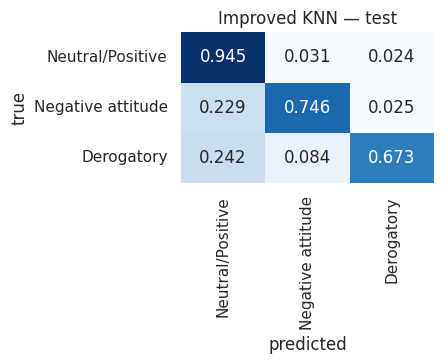

In [12]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# BEFORE: original KNN (K = 6, Euclidean, full TF-IDF)
before = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=6, metric="euclidean").fit(Xtr, y_train).predict(Xte))

# Grid search on the validation set
grid = []
for n_comp in [100, 200, 300]:
    svd = TruncatedSVD(n_components=n_comp, random_state=SEED).fit(Xtr)
    Ztr, Zva = normalize(svd.transform(Xtr)), normalize(svd.transform(Xva))
    for k in [1, 3, 5, 7, 11, 15, 25]:
        for w in ["uniform", "distance"]:
            m = KNeighborsClassifier(n_neighbors=k, weights=w, metric="euclidean", n_jobs=-1).fit(Ztr, y_train)
            grid.append({"SVD dims": n_comp, "K": k, "weights": w,
                         "Val acc": accuracy_score(y_val, m.predict(Zva))})
grid = pd.DataFrame(grid).sort_values("Val acc", ascending=False)
print("Top settings on validation:")
display(grid.head(8))

# AFTER: retrain with the best settings, evaluate once on test
b = grid.iloc[0]
svd = TruncatedSVD(n_components=int(b["SVD dims"]), random_state=SEED).fit(Xtr)
knn_best = KNeighborsClassifier(n_neighbors=int(b["K"]), weights=b["weights"],
                                metric="euclidean", n_jobs=-1).fit(normalize(svd.transform(Xtr)), y_train)
pred_knn = knn_best.predict(normalize(svd.transform(Xte)))
after = accuracy_score(y_test, pred_knn)

display(pd.DataFrame({"Model": ["KNN original (K=6)", f"KNN + SVD{int(b['SVD dims'])} + K={int(b['K'])}, {b['weights']}"],
                      "Test acc": [before, after],
                      "Macro F1": [None, f1_score(y_test, pred_knn, average="macro")]}).round(4))
print(f"Improvement: {before:.4f} -> {after:.4f}  (+{(after-before)*100:.1f} points)")
plot_cm(y_test, pred_knn, "Improved KNN — test", "cm_knn_improved.png")